In [1]:
# 도커 환경은 켤 때마다 새로 깔끔해지므로, 필요한 라이브러리를 한 번 설치해 줍니다.
!pip install monai SimpleITK pydicom nibabel scikit-learn pandas matplotlib

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 8.8 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 9.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.6 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 10.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 6.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.1/532.1 MB 4.9 MB/s eta 0:00:0000:0100:02m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 9.9 MB/s eta 0:00:00:00:010:02m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 9.6 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 128GB RAM을 믿고 넉넉하게 10,000개의 가상 ECG 샘플을 만듭니다.
num_samples = 10000
signal_len = 187  # MIT-BIH 데이터셋의 표준 신호 길이

# 정상 신호와 비정상(노이즈) 신호의 베이스 파형 정의
t = np.linspace(0, 1, signal_len)
normal_wave = np.sin(2 * np.pi * 5 * t)
abnormal_wave = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 20 * t)

X_data, y_data = [], []
for _ in range(num_samples // 2):
    # 가우시안 노이즈를 섞어서 무작위성 부여
    X_data.append(normal_wave + np.random.normal(0, 0.1, signal_len))
    y_data.append(0)  # 정상 라벨
    X_data.append(abnormal_wave + np.random.normal(0, 0.1, signal_len))
    y_data.append(1)  # 비정상 라벨

# 파이토치 텐서로 변환 [배치 크기, 채널 수(1), 신호 길이]
X = torch.tensor(np.array(X_data), dtype=torch.float32).unsqueeze(1).cuda()
y = torch.tensor(np.array(y_data), dtype=torch.float32).unsqueeze(1).cuda()

print(f"✅ 데이터가 GPU({torch.cuda.get_device_name(0)}) 메모리에 탑재되었습니다.")
print(f"현재 할당된 VRAM: {torch.cuda.memory_allocated(0)/1024**2:.2f} MB")

✅ 데이터가 GPU(NVIDIA GeForce RTX 2070) 메모리에 탑재되었습니다.
현재 할당된 VRAM: 7.17 MB


In [3]:
class ECG1DCNN(nn.Module):
    def __init__(self):
        super(ECG1DCNN, self).__init__()
        # 시계열 패턴을 추출하는 합성곱 레이어
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        # 추출된 특징을 바탕으로 0 또는 1을 분류하는 레이어
        self.classifier = nn.Sequential(
            nn.Linear(64 * 46, 128), # 패딩 추가로 인한 최종 길이 계산 반영
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid() # 0~1 사이의 확률값 출력
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1) # 1차원으로 쫙 펼치기
        return self.classifier(x)

model = ECG1DCNN().cuda() # 모델도 GPU로 전송
criterion = nn.BCELoss() # 이진 분류용 손실함수
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("✅ 1D-CNN AI 모델이 RTX 2070 엔진 위에 세팅되었습니다.")

✅ 1D-CNN AI 모델이 RTX 2070 엔진 위에 세팅되었습니다.


In [4]:
epochs = 50
print("🚀 학습 루프를 가동합니다...")

for epoch in range(epochs):
    model.train()
    
    # 1. 순전파: 모델에게 문제 풀게 하기
    outputs = model(X)
    loss = criterion(outputs, y)
    
    # 2. 역전파: 틀린 만큼 반성하고 가중치 수정하기
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss(오차): {loss.item():.4f}")

print("✨ 학습 완료! 인공지능이 정상/비정상 심박 패턴을 모두 마스터했습니다.")

🚀 학습 루프를 가동합니다...
Epoch [10/50], Loss(오차): 0.0696
Epoch [20/50], Loss(오차): 0.0003
Epoch [30/50], Loss(오차): 0.0000
Epoch [40/50], Loss(오차): 0.0000
Epoch [50/50], Loss(오차): 0.0000
✨ 학습 완료! 인공지능이 정상/비정상 심박 패턴을 모두 마스터했습니다.


In [5]:
# 이 코드가 실행되면 도커를 지워도 6TB 하드디스크에 가중치 파일이 영구 격리 저장됩니다.
model_save_path = "/workspace/medical_datasets/ecg_model_v1.pth"
torch.save(model.state_dict(), model_save_path)

print(f"💾 모델의 지식이 다음 경로에 안전하게 저장되었습니다: {model_save_path}")

💾 모델의 지식이 다음 경로에 안전하게 저장되었습니다: /workspace/medical_datasets/ecg_model_v1.pth


In [5]:
# 현재 폴더 구조 한눈에 보기
!ls -R /workspace

/workspace:
Untitled.ipynb	    medical_datasets	 study_1.ipynb
hello_research.txt  myo_data		 study_2.ipynb
lost+found	    myo_emg_dataset.zip  test_1.ipynb

/workspace/lost+found:

/workspace/medical_datasets:
ecg.ipynb  ecg_mitbih  ecg_model_v1.pth  ecg_study  emg_study  share

/workspace/medical_datasets/ecg_mitbih:

/workspace/medical_datasets/ecg_study:

/workspace/medical_datasets/emg_study:
emg.ipynb

/workspace/medical_datasets/share:
archive  archive.zip

/workspace/medical_datasets/share/archive:
mitbih_ecg_model_final.pth  mitbih_train.csv	ptbdb_normal.csv
mitbih_test.csv		    ptbdb_abnormal.csv

/workspace/myo_data:
myo_ds_30l_10ol.npz  myo_ds_30l_10ol_kmeans_labels.npz


진짜 심전도 데이터를 128GB RAM으로 끌어올리는 중...
✅ 로드 성공! 총 87554개의 환자 심박 데이터가 준비되었습니다.


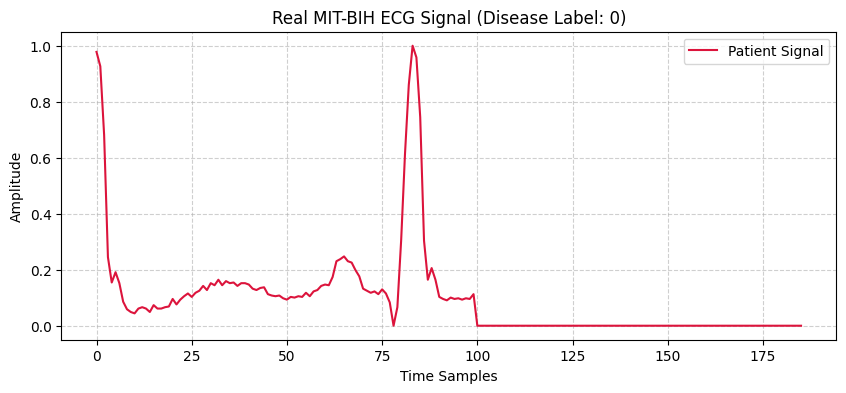

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 6TB 하드 내부의 실제 파일 위치 지정
real_data_path = "/workspace/medical_datasets/share/archive/mitbih_train.csv"

print("진짜 심전도 데이터를 128GB RAM으로 끌어올리는 중...")
df = pd.read_csv(real_data_path, header=None)
print(f"✅ 로드 성공! 총 {df.shape[0]}개의 환자 심박 데이터가 준비되었습니다.")

# 2. 진짜 환자의 심장 박동 눈으로 확인하기
plt.figure(figsize=(10, 4))
# 0번부터 186번 열까지가 하나의 심박 파형입니다.
plt.plot(df.iloc[0, :186], label="Patient Signal", color="crimson") 
plt.title(f"Real MIT-BIH ECG Signal (Disease Label: {int(df.iloc[0, 187])})")
plt.xlabel("Time Samples")
plt.ylabel("Amplitude")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# 1. 특징 데이터(X)와 정답 라벨(y) 분리
X_real = df.iloc[:, :186].values # 0~185번 열
y_real = df.iloc[:, 187].values  # 187번 열 (정답)

# 2. 학습용(80%)과 검증용(20%) 데이터로 분리
X_train, X_val, y_train, y_val = train_test_split(X_real, y_real, test_size=0.2, random_state=42)

# 3. 파이토치 텐서로 변환 후 GPU 연산을 위한 구조[배치, 채널(1), 길이(186)] 설정
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32).unsqueeze(1),
    torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
)
val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32).unsqueeze(1),
    torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
)

# 4. 128GB RAM을 믿고 배치를 512로 크게 잡아서 GPU로 빠르게 쏩니다.
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)

print(f"✅ 실전 데이터셋 분리 완료! 학습 배치 개수: {len(train_loader)}")

✅ 실전 데이터셋 분리 완료! 학습 배치 개수: 137


In [8]:
import torch.nn as nn
import torch.optim as optim

class RealECGNet(nn.Module):
    def __init__(self):
        super(RealECGNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32), # 실제 데이터의 안정을 위한 배치 정규화
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 46, 128),
            nn.ReLU(),
            nn.Dropout(0.3), # 과적합 방지
            nn.Linear(128, 5) # 0~4번까지의 부정맥 종류 총 5개 분류!
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

# 모델 생성 및 다중 분류를 위한 CrossEntropy 손실함수 설정
model = RealECGNet().cuda()
criterion = nn.CrossEntropyLoss() # 5개 클래스 분류용
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("✅ 실제 부정맥 진단용 1D-CNN 모델이 GPU에 장착되었습니다.")

✅ 실제 부정맥 진단용 1D-CNN 모델이 GPU에 장착되었습니다.


In [9]:
epochs = 10
print("🚀 진짜 환자 데이터로 의공학 인공지능 학습을 시작합니다...")

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for batch_X, batch_y in train_loader:
        # 데이터를 GPU로 전송
        batch_X, batch_y = batch_X.cuda(), batch_y.long().cuda().squeeze(1)
        
        # 예측 및 오차 계산
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        
        # 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    print(f"Epoch [{epoch+1}/{epochs}], 평점 Loss: {total_loss/len(train_loader):.4f}")

print("✨ 진짜 환자 데이터셋 학습 완료!")

🚀 진짜 환자 데이터로 의공학 인공지능 학습을 시작합니다...
Epoch [1/10], 평점 Loss: 0.2507
Epoch [2/10], 평점 Loss: 0.1290
Epoch [3/10], 평점 Loss: 0.1057
Epoch [4/10], 평점 Loss: 0.0927
Epoch [5/10], 평점 Loss: 0.0836
Epoch [6/10], 평점 Loss: 0.0773
Epoch [7/10], 평점 Loss: 0.0700
Epoch [8/10], 평점 Loss: 0.0648
Epoch [9/10], 평점 Loss: 0.0622
Epoch [10/10], 평점 Loss: 0.0571
✨ 진짜 환자 데이터셋 학습 완료!


In [10]:
final_save_path = "/workspace/medical_datasets/share/archive/mitbih_ecg_model_final.pth"
torch.save(model.state_dict(), final_save_path)
print(f"💾 실제 부정맥 진단 AI 가중치가 6TB 하드에 저장되었습니다:\n{final_save_path}")

💾 실제 부정맥 진단 AI 가중치가 6TB 하드에 저장되었습니다:
/workspace/medical_datasets/share/archive/mitbih_ecg_model_final.pth


In [11]:
# 맨 앞에 느낌표(!)를 붙여서 주피터 안에서 바로 설치합니다.
!pip install seaborn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip


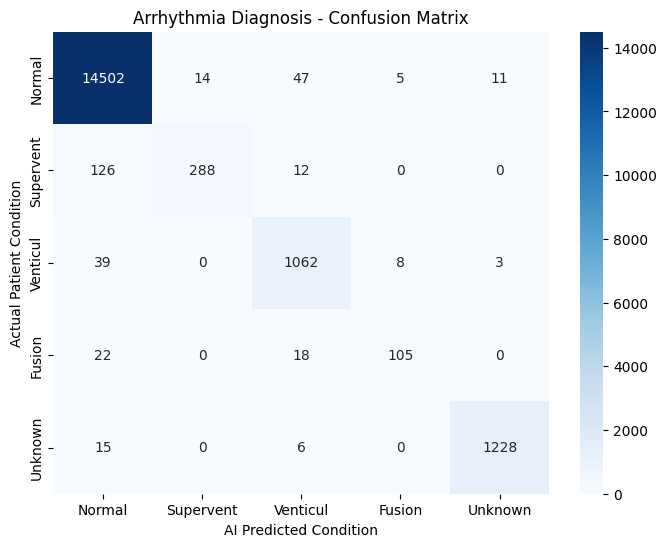


--- 🩺 AI 의공학 진단 성적표 ---
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     14579
   Supervent       0.95      0.68      0.79       426
    Venticul       0.93      0.96      0.94      1112
      Fusion       0.89      0.72      0.80       145
     Unknown       0.99      0.98      0.99      1249

    accuracy                           0.98     17511
   macro avg       0.95      0.87      0.90     17511
weighted avg       0.98      0.98      0.98     17511



In [12]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval() # 모델을 평가 모드로 전환 (Dropout 등을 끕니다)
all_preds = []
all_labels = []

# 검증 데이터를 넣어서 AI의 예측값 모으기
with torch.no_grad():
    for batch_X, batch_y in val_loader:
        batch_X = batch_X.cuda()
        outputs = model(batch_X)
        
        # 가장 확률이 높은 클래스 번호 추출
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch_y.numpy().flatten())

# 1. 의료 인공지능의 핵심 성적표: 혼동 행렬(Confusion Matrix) 그리기
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Normal", "Supervent", "Venticul", "Fusion", "Unknown"],
            yticklabels=["Normal", "Supervent", "Venticul", "Fusion", "Unknown"])
plt.title("Arrhythmia Diagnosis - Confusion Matrix")
plt.ylabel("Actual Patient Condition")
plt.xlabel("AI Predicted Condition")
plt.show()

# 2. 정밀도(Precision), 재현율(Recall), F1-Score 출력
print("\n--- 🩺 AI 의공학 진단 성적표 ---")
print(classification_report(all_labels, all_preds, 
                            target_names=["Normal", "Supervent", "Venticul", "Fusion", "Unknown"]))

In [13]:
import torch
import numpy as np

# 학습 데이터의 정답 라벨들만 모아서 개수를 셉니다.
labels_train = y_train.astype(int)
class_counts = np.bincount(labels_train)
total_samples = len(labels_train)
num_classes = len(class_counts)

# 역수 가중치 공식 (많을수록 가중치 감소, 적을수록 가중치 증가)
# 가중치 = 전체 샘플 수 / (클래스 개수 * 해당 클래스 샘플 수)
class_weights = total_samples / (num_classes * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).cuda()

print("--- 📊 계산된 클래스별 AI 가중치 ---")
labels_name = ["Normal", "Supervent", "Venticul", "Fusion", "Unknown"]
for name, weight, count in zip(labels_name, class_weights, class_counts):
    print(f"[{name:<9}] 데이터 개수: {count:>5}개 ➡️ AI 편애 가중치: {weight:.2f}배")

--- 📊 계산된 클래스별 AI 가중치 ---
[Normal   ] 데이터 개수: 57892개 ➡️ AI 편애 가중치: 0.24배
[Supervent] 데이터 개수:  1797개 ➡️ AI 편애 가중치: 7.80배
[Venticul ] 데이터 개수:  4676개 ➡️ AI 편애 가중치: 3.00배
[Fusion   ] 데이터 개수:   496개 ➡️ AI 편애 가중치: 28.24배
[Unknown  ] 데이터 개수:  5182개 ➡️ AI 편애 가중치: 2.70배


In [14]:
import torch.nn as nn
import torch.optim as optim

# 새 모델 생성 및 업그레이드된 손실함수 정의 (weight 추가!)
balanced_model = RealECGNet().cuda()
criterion_balanced = nn.CrossEntropyLoss(weight=class_weights_tensor) 
optimizer = optim.Adam(balanced_model.parameters(), lr=0.001)

epochs = 10
print("🚀 가중치 밸런스를 맞춘 진짜 환자 데이터셋 학습 시작...")

for epoch in range(epochs):
    balanced_model.train()
    total_loss = 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.cuda(), batch_y.long().cuda().squeeze(1)
        
        outputs = balanced_model(batch_X)
        loss = criterion_balanced(outputs, batch_y) # 가중치 반영 채점
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    print(f"Epoch [{epoch+1}/{epochs}], 평점 Loss: {total_loss/len(train_loader):.4f}")

print("✨ 가중치 반영 학습 완료!")

🚀 가중치 밸런스를 맞춘 진짜 환자 데이터셋 학습 시작...
Epoch [1/10], 평점 Loss: 0.5589
Epoch [2/10], 평점 Loss: 0.3538
Epoch [3/10], 평점 Loss: 0.2872
Epoch [4/10], 평점 Loss: 0.2489
Epoch [5/10], 평점 Loss: 0.2136
Epoch [6/10], 평점 Loss: 0.1964
Epoch [7/10], 평점 Loss: 0.1793
Epoch [8/10], 평점 Loss: 0.1638
Epoch [9/10], 평점 Loss: 0.1480
Epoch [10/10], 평점 Loss: 0.1353
✨ 가중치 반영 학습 완료!


In [15]:
balanced_model.eval()
all_preds_b = []
all_labels_b = []

with torch.no_grad():
    for batch_X, batch_y in val_loader:
        batch_X = batch_X.cuda()
        outputs = balanced_model(batch_X)
        _, preds = torch.max(outputs, 1)
        all_preds_b.extend(preds.cpu().numpy())
        all_labels_b.extend(batch_y.numpy().flatten())

print("\n--- 🩺 [업그레이드] AI 의공학 진단 성적표 ---")
print(classification_report(all_labels_b, all_preds_b, 
                            target_names=["Normal", "Supervent", "Venticul", "Fusion", "Unknown"]))


--- 🩺 [업그레이드] AI 의공학 진단 성적표 ---
              precision    recall  f1-score   support

      Normal       1.00      0.90      0.95     14579
   Supervent       0.41      0.92      0.56       426
    Venticul       0.81      0.95      0.87      1112
      Fusion       0.18      0.94      0.30       145
     Unknown       0.93      0.99      0.96      1249

    accuracy                           0.91     17511
   macro avg       0.66      0.94      0.73     17511
weighted avg       0.96      0.91      0.93     17511



In [16]:
import torch
import numpy as np

# 학습 데이터 개수 기반 다시 세팅
labels_train = y_train.astype(int)
class_counts = np.bincount(labels_train)
total_samples = len(labels_train)
num_classes = len(class_counts)

# 💡 가중치 공식에 np.sqrt(루트)를 씌워 극단적인 편애를 완화합니다.
smooth_weights = np.sqrt(total_samples / (num_classes * class_counts))
smooth_weights_tensor = torch.tensor(smooth_weights, dtype=torch.float32).cuda()

print("--- 📊 계산된 [부드러운] AI 가중치 ---")
labels_name = ["Normal", "Supervent", "Venticul", "Fusion", "Unknown"]
for name, weight, count in zip(labels_name, smooth_weights, class_counts):
    print(f"[{name:<9}] 데이터 개수: {count:>5}개 ➡️ AI 완화 가중치: {weight:.2f}배")

--- 📊 계산된 [부드러운] AI 가중치 ---
[Normal   ] 데이터 개수: 57892개 ➡️ AI 완화 가중치: 0.49배
[Supervent] 데이터 개수:  1797개 ➡️ AI 완화 가중치: 2.79배
[Venticul ] 데이터 개수:  4676개 ➡️ AI 완화 가중치: 1.73배
[Fusion   ] 데이터 개수:   496개 ➡️ AI 완화 가중치: 5.31배
[Unknown  ] 데이터 개수:  5182개 ➡️ AI 완화 가중치: 1.64배


In [17]:
import torch.nn as nn
import torch.optim as optim

# 부드러운 가중치를 탑재한 새 모델과 손실함수
smooth_model = RealECGNet().cuda()
criterion_smooth = nn.CrossEntropyLoss(weight=smooth_weights_tensor)
optimizer = optim.Adam(smooth_model.parameters(), lr=0.001)

epochs = 10
print("🚀 황금 밸런스 세팅으로 진짜 환자 데이터 학습 시작...")

for epoch in range(epochs):
    smooth_model.train()
    total_loss = 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.cuda(), batch_y.long().cuda().squeeze(1)
        
        outputs = smooth_model(batch_X)
        loss = criterion_smooth(outputs, batch_y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    print(f"Epoch [{epoch+1}/{epochs}], 평점 Loss: {total_loss/len(train_loader):.4f}")

print("✨ 황금 밸런스 모델 학습 완료!")

🚀 황금 밸런스 세팅으로 진짜 환자 데이터 학습 시작...
Epoch [1/10], 평점 Loss: 0.4280
Epoch [2/10], 평점 Loss: 0.2517
Epoch [3/10], 평점 Loss: 0.2075
Epoch [4/10], 평점 Loss: 0.1791
Epoch [5/10], 평점 Loss: 0.1616
Epoch [6/10], 평점 Loss: 0.1436
Epoch [7/10], 평점 Loss: 0.1352
Epoch [8/10], 평점 Loss: 0.1234
Epoch [9/10], 평점 Loss: 0.1110
Epoch [10/10], 평점 Loss: 0.1017
✨ 황금 밸런스 모델 학습 완료!


In [18]:
from sklearn.metrics import classification_report

smooth_model.eval()
all_preds_s = []
all_labels_s = []

with torch.no_grad():
    for batch_X, batch_y in val_loader:
        batch_X = batch_X.cuda()
        outputs = smooth_model(batch_X)
        _, preds = torch.max(outputs, 1)
        all_preds_s.extend(preds.cpu().numpy())
        all_labels_s.extend(batch_y.numpy().flatten())

print("\n--- 🩺 [황금 밸런스] AI 의공학 진단 성적표 ---")
print(classification_report(all_labels_s, all_preds_s, 
                            target_names=["Normal", "Supervent", "Venticul", "Fusion", "Unknown"]))


--- 🩺 [황금 밸런스] AI 의공학 진단 성적표 ---
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98     14579
   Supervent       0.79      0.79      0.79       426
    Venticul       0.85      0.97      0.90      1112
      Fusion       0.46      0.83      0.59       145
     Unknown       0.97      0.99      0.98      1249

    accuracy                           0.97     17511
   macro avg       0.81      0.91      0.85     17511
weighted avg       0.97      0.97      0.97     17511

